## Final Project Analysis

This notebook combines findings from the previous four weeks of the internship. It summarizes customer subscription patterns, statistical analysis, and machine learning performance to support data-driven marketing recommendations.



In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [10]:
# load dataset
df = pd.read_csv("../../data/bank-full.csv", sep=",")
df.head(5)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [11]:
# check rows and columns

df.shape

(45211, 17)

In [12]:
# count subscription outcomes
print(df["y"].value_counts())

# calculate percentages
print("\nSubscription Percentage:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

y
no     39922
yes     5289
Name: count, dtype: int64

Subscription Percentage:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [13]:
job_subscription = (
    df.groupby("job")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print(job_subscription.round(2))

job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: y, dtype: float64


# Subscription Rate Chart

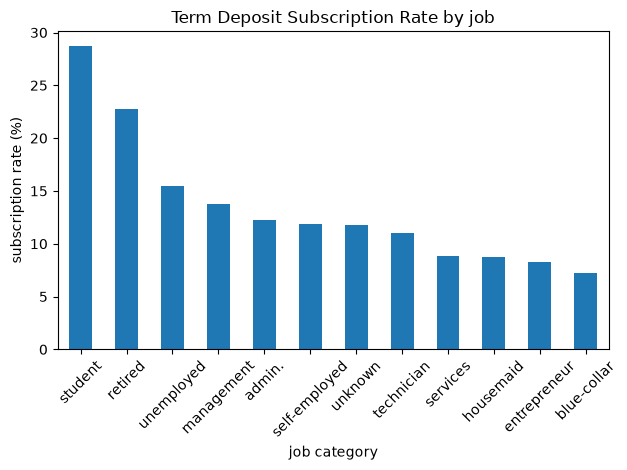

In [14]:
plt.Figure(figsize=(10, 5))

job_subscription.plot(kind="bar")
plt.title("Term Deposit Subscription Rate by job")
plt.xlabel("job category")
plt.ylabel("subscription rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../charts/job_subscription_rate.png", dpi=300, bbox_inches = "tight")
plt.show()

In [15]:
# Analyze Subscription by Age Group
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["18–25", "26–35", "36–45", "46–55", "56–65", "66+"]
)

age_subscription = (
    df.groupby("age_group", observed=False)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

print(age_subscription.round(2))

age_group
18–25    23.95
26–35    12.00
36–45     9.39
46–55     9.35
56–65    14.12
66+      42.61
Name: y, dtype: float64


# Create the Age Group Chart

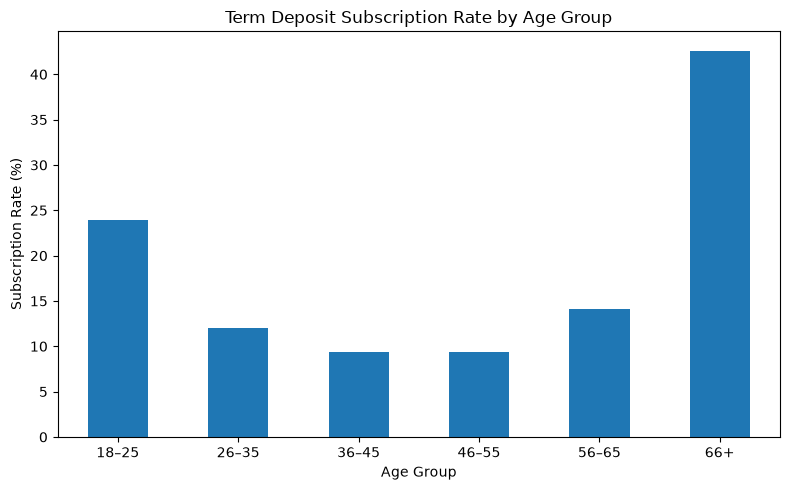

In [16]:
plt.figure(figsize=(8, 5))

age_subscription.plot(kind="bar")
plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../charts/age_subscription_rate.png", dpi=300, bbox_inches="tight")
plt.show()

## Statistical Analysis and Machine Learning Results

Week 3 examined relationships between customer characteristics and term-deposit subscriptions using hypothesis testing.

Week 4 developed and evaluated Logistic Regression and Decision Tree classification models. Logistic Regression achieved 84.57% accuracy, while Decision Tree achieved 83.00% accuracy. Logistic Regression was selected as the preferred model based on its overall performance.

## Business Recommendations

1. **Target High-Performing Segments:** Focus marketing campaigns on customer groups with higher subscription rates, including students and retired customers.

2. **Age-Based Campaigns:** Tailor marketing strategies to different age groups based on their subscription patterns.

3. **Data-Driven Targeting:** Use machine learning predictions to help prioritize customers for future marketing campaigns.

4. **Improve Campaign Efficiency:** Evaluate campaign outcomes regularly and refine targeting strategies using customer data.

## Key Findings

- The dataset contains 45,211 customer records and 17 columns.
- Overall, 11.70% of customers subscribed to the term deposit.
- Subscription rates vary across job categories and age groups.
- Logistic Regression achieved 84.57% accuracy, outperforming the Decision Tree model's 83.00% accuracy.

## Limitations

- The dataset contains an imbalanced target variable.
- Model accuracy alone does not fully measure performance on the minority class.
- Historical customer data may not represent future customer behavior.

## Conclusion

This project combined exploratory data analysis, statistical hypothesis testing, and machine learning to understand term-deposit subscription patterns. The findings can help businesses improve customer targeting and make more informed marketing decisions. Further improvements could include testing additional models and evaluating their performance using precision, recall, and F1-score.